In [3]:
import numpy as np

apple = np.load('full_numpy_bitmap_apple.npy')
cat = np.load('full_numpy_bitmap_cat.npy')
star = np.load('full_numpy_bitmap_star.npy')

print("Apple shape:", apple.shape)
print("Cat shape:", cat.shape)
print("Star shape:", star.shape)

Apple shape: (144722, 784)
Cat shape: (123202, 784)
Star shape: (137619, 784)


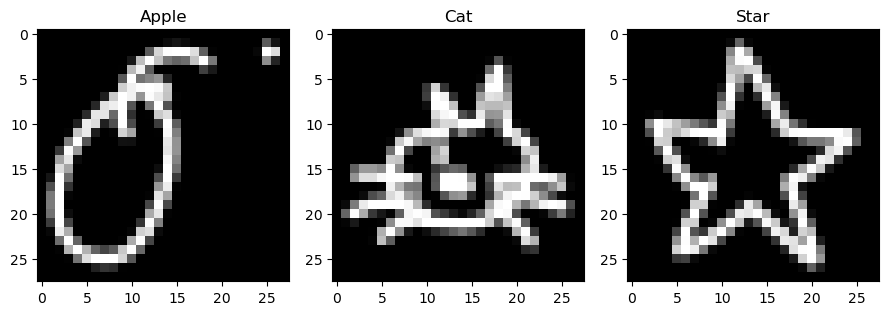

In [4]:
import matplotlib.pyplot as plt

# Each row is a flattened 28x28 image (784 pixels)
# Let's reshape and visualize one example of each

plt.figure(figsize=(9, 3))

plt.subplot(1, 3, 1)
plt.imshow(apple[0].reshape(28, 28), cmap='gray')
plt.title("Apple")

plt.subplot(1, 3, 2)
plt.imshow(cat[0].reshape(28, 28), cmap='gray')
plt.title("Cat")

plt.subplot(1, 3, 3)
plt.imshow(star[0].reshape(28, 28), cmap='gray')
plt.title("Star")

plt.tight_layout()
plt.show()

In [5]:
from sklearn.model_selection import train_test_split

# Assign labels: 0 for apple, 1 for cat, 2 for star
apple_labels = np.zeros(len(apple))
cat_labels = np.ones(len(cat))
star_labels = np.full(len(star), 2)

# Stack data and labels
X = np.vstack([apple, cat, star])
y = np.concatenate([apple_labels, cat_labels, star_labels])

# Normalize pixel values (0-1)
X = X / 255.0

# Split into train/test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Train shape: (324434, 784)
Test shape: (81109, 784)


In [4]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv2D, MaxPooling2D, Flatten, Dropout, Reshape
from tensorflow.keras.utils import to_categorical

# Convert labels to one-hot vectors
y_train_cat = to_categorical(y_train, 3)
y_test_cat = to_categorical(y_test, 3)

# Reshape input for CNN: (num_samples, 28, 28, 1)
X_train_reshaped = X_train.reshape(-1, 28, 28, 1)
X_test_reshaped = X_test.reshape(-1, 28, 28, 1)

# Build the model
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    MaxPooling2D(2, 2),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),
    Flatten(),
    Dropout(0.4),
    Dense(128, activation='relu'),
    Dense(3, activation='softmax')  # 3 output classes
])

# Compile the model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Train the model
history = model.fit(X_train_reshaped, y_train_cat, epochs=10, validation_split=0.2, batch_size=64)

/Users/kaustubh/miniforge3/envs/doodle/lib/python3.9/site-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
4056/4056 ━━━━━━━━━━━━━━━━━━━━ 659s 162ms/step - accuracy: 0.9408 - loss: 0.1548 - val_accuracy: 0.9787 - val_loss: 0.0611
Epoch 2/10
4056/4056 ━━━━━━━━━━━━━━━━━━━━ 1807s 446ms/step - accuracy: 0.9798 - loss: 0.0564 - val_accuracy: 0.9848 - val_loss: 0.0435
Epoch 3/10
4056/4056 ━━━━━━━━━━━━━━━━━━━━ 414s 102ms/step - accuracy: 0.9840 - loss: 0.0450 - val_accuracy: 0.9859 - val_loss: 0.0384
Epoch 4/10
4056/4056 ━━━━━━━━━━━━━━━━━━━━ 832s 205ms/step - accuracy: 0.9860 - loss: 0.0380 - val_accuracy: 0.9858 - val_loss: 0.0374
Epoch 5/10
4056/4056 ━━━━━━━━━━━━━━━━━━━━ 51s 12ms/step - accuracy: 0.9872 - loss: 0.0343 - val_accuracy: 0.9862 - val_loss: 0.0372
Epoch 6/10
4056/4056 ━━━━━━━━━━━━━━━━━━━━ 49s 12ms/step - accuracy: 0.9879 - loss: 0.0321 - val_accuracy: 0.9869 - val_loss: 0.0354
Epoch 7/10
4056/4056 ━━━━━━━━━━━━━━━━━━━━ 50s 12ms/step - accuracy: 0.9892 - loss: 0.0290 - val_accuracy: 0.9868 - val_loss: 0.0361
Epoch 8/10
4056/4056 ━━━━━━━━━━━━━━━━━━━━ 49s 12ms/step - accuracy:

In [6]:
# Add labels to each class
apple_labels = np.zeros((apple.shape[0], 1))   # Label 0
cat_labels = np.ones((cat.shape[0], 1))        # Label 1
star_labels = np.full((star.shape[0], 1), 2)   # Label 2

# Concatenate data and labels
X = np.vstack([apple, cat, star])
y = np.vstack([apple_labels, cat_labels, star_labels]).flatten()

print("Combined shape:", X.shape)
print("Labels shape:", y.shape)

Combined shape: (405543, 784)
Labels shape: (405543,)


In [7]:
from sklearn.utils import shuffle
from sklearn.model_selection import train_test_split

# Shuffle the data
X, y = shuffle(X, y, random_state=42)

# Normalize pixel values to [0, 1]
X = X / 255.0

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Reshape for CNN input (samples, 28, 28, 1)
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

Training set shape: (324434, 28, 28, 1)
Testing set shape: (81109, 28, 28, 1)


In [7]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Define the CNN model
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    layers.MaxPooling2D((2, 2)),
    
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(3, activation='softmax')  # 3 classes: apple, cat, star
])

# Compile the model
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Train the model
history = model.fit(X_train, y_train, epochs=5, batch_size=128,
                    validation_data=(X_test, y_test))

/Users/kaustubh/miniforge3/envs/doodle/lib/python3.9/site-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
2535/2535 ━━━━━━━━━━━━━━━━━━━━ 45s 18ms/step - accuracy: 0.9463 - loss: 0.1506 - val_accuracy: 0.9778 - val_loss: 0.0612
Epoch 2/5
2535/2535 ━━━━━━━━━━━━━━━━━━━━ 47s 19ms/step - accuracy: 0.9809 - loss: 0.0537 - val_accuracy: 0.9811 - val_loss: 0.0514
Epoch 3/5
2535/2535 ━━━━━━━━━━━━━━━━━━━━ 49s 19ms/step - accuracy: 0.9856 - loss: 0.0400 - val_accuracy: 0.9848 - val_loss: 0.0409
Epoch 4/5
2535/2535 ━━━━━━━━━━━━━━━━━━━━ 50s 20ms/step - accuracy: 0.9883 - loss: 0.0316 - val_accuracy: 0.9860 - val_loss: 0.0382
Epoch 5/5
2535/2535 ━━━━━━━━━━━━━━━━━━━━ 52s 21ms/step - accuracy: 0.9905 - loss: 0.0258 - val_accuracy: 0.9861 - val_loss: 0.0394


In [2]:
# Plot accuracy
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# Plot loss
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step


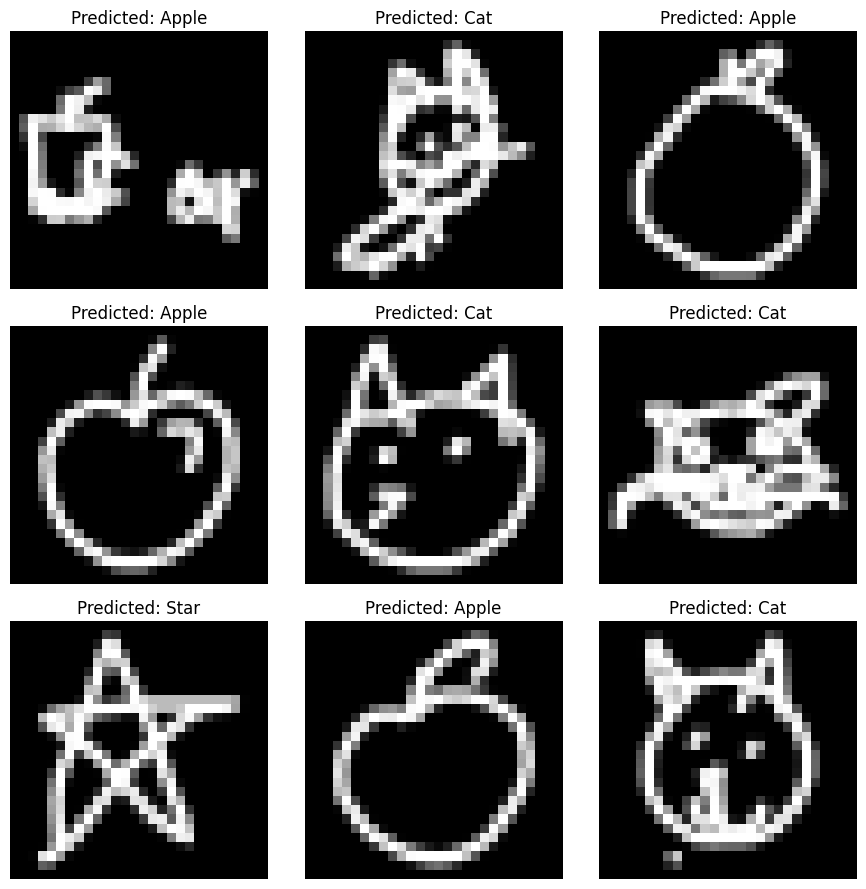

In [9]:
# Class labels
class_names = ['Apple', 'Cat', 'Star']

# Predict first 9 images from test set
predictions = model.predict(X_test[:9])
predicted_labels = np.argmax(predictions, axis=1)

plt.figure(figsize=(9, 9))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(X_test[i].reshape(28, 28), cmap='gray')
    plt.title(f"Predicted: {class_names[predicted_labels[i]]}")
    plt.axis('off')
plt.tight_layout()
plt.show()

In [10]:
model.save("doodle_classifier_model.h5")


In [11]:
model.save("doodle_classifier_model.keras")

Apple shape: (144722, 784)
Cat shape: (123202, 784)
Star shape: (137619, 784)

Apple sample (flattened):
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0  11  21  12   0   0   0   0   0   0   0   0  92
  20   0   0   0   0   0   0   0   0   0   0   0   0   0  91 213 253 255
 255 222  95   3   0   0   0   0   7 255 222   0   0   0   0   0   0   0
   0   0   0   0  24 190 255 196 118 100 109 196 255 121   0   0   0   0
   0 141  35   0   0   0   0   0   0   0   0   0   0   1 185 241  94   1
   0   0   0   0  63  25   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0  89 255 115 133 150  37   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0 207 241 252
 255 250 199   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0  30 200 255 242 149 252 232 195   3   0   0   0   0
   0   0   0   0  

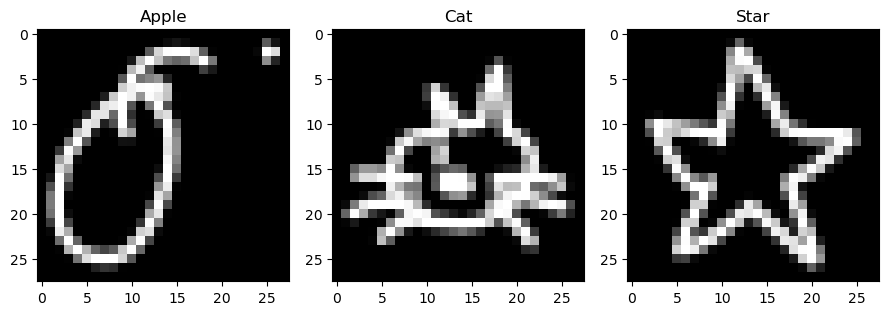

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# Load the data
apple = np.load('full_numpy_bitmap_apple.npy')
cat = np.load('full_numpy_bitmap_cat.npy')
star = np.load('full_numpy_bitmap_star.npy')

# Print shapes of all datasets
print("Apple shape:", apple.shape)
print("Cat shape:", cat.shape)
print("Star shape:", star.shape)

# Show flattened sample (first image)
print("\nApple sample (flattened):\n", apple[0])
print("\nCat sample (flattened):\n", cat[0])
print("\nStar sample (flattened):\n", star[0])

# Show reshaped image data
print("\nApple sample (reshaped to 28x28):\n", apple[0].reshape(28, 28))
print("\nCat sample (reshaped to 28x28):\n", cat[0].reshape(28, 28))
print("\nStar sample (reshaped to 28x28):\n", star[0].reshape(28, 28))

# Visualize the first few samples
plt.figure(figsize=(9, 3))

plt.subplot(1, 3, 1)
plt.imshow(apple[0].reshape(28, 28), cmap='gray')
plt.title("Apple")

plt.subplot(1, 3, 2)
plt.imshow(cat[0].reshape(28, 28), cmap='gray')
plt.title("Cat")

plt.subplot(1, 3, 3)
plt.imshow(star[0].reshape(28, 28), cmap='gray')
plt.title("Star")

plt.tight_layout()
plt.show()

In [10]:
print("Apple sample (reshaped):\n", apple[0].reshape(28, 28))

Apple sample (reshaped):
 [[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0  11  21  12   0
    0   0   0   0   0   0   0  92  20   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0  91 213 253 255 255 222
   95   3   0   0   0   0   7 255 222   0]
 [  0   0   0   0   0   0   0   0   0   0  24 190 255 196 118 100 109 196
  255 121   0   0   0   0   0 141  35   0]
 [  0   0   0   0   0   0   0   0   0   1 185 241  94   1   0   0   0   0
   63  25   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0  89 255 115 133 150  37   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0 207 241 252 255 250 199   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0  30 200 255 242 149 252 232 195   3   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0  39 225 238 